## Практическое задание №7

#### по дисциплине "Введение в анализ данных"

*Работу выполнил*: Евсеев Григорий, 3826Б1ПМад1

### Часть 2.

#### Пункт 1.

Импорт библиотек:

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import minimize

Генерация выборки объемом 500 значений из пуассоновского распределения с параметром $\lambda$ = 1.5:

In [2]:
size = 500
lam = 1.5

sample = np.random.poisson(lam, size)
print(sample)

[2 3 0 0 2 0 0 1 0 2 1 1 2 3 2 1 3 2 0 1 0 1 0 1 1 2 2 2 2 0 0 1 1 2 1 1 2
 5 2 3 0 1 3 1 3 2 1 1 0 2 0 1 1 3 0 1 1 1 2 0 1 3 0 3 3 1 4 0 1 2 1 3 0 4
 1 4 1 0 1 2 3 3 2 2 2 1 0 3 1 2 2 1 0 2 0 0 3 1 3 0 0 3 2 1 0 1 1 2 1 0 1
 4 6 0 4 2 0 2 3 3 2 0 0 0 2 4 2 0 0 1 1 2 1 2 1 1 1 2 0 1 5 1 3 0 6 1 1 1
 2 0 2 3 2 0 0 2 1 0 2 0 2 1 2 4 0 1 5 2 1 2 2 1 2 3 3 2 1 1 0 1 1 3 0 0 1
 1 1 1 2 2 0 1 1 2 4 2 2 0 3 0 0 0 2 1 0 3 1 3 1 0 3 1 2 0 1 1 2 1 1 3 1 0
 1 0 1 3 1 0 0 3 2 1 3 2 2 2 0 3 3 3 2 1 2 2 2 1 2 2 1 0 1 0 3 0 0 1 0 3 1
 1 3 2 0 2 3 3 0 2 2 3 1 2 0 0 0 1 0 1 3 1 2 1 2 2 3 2 1 4 2 2 2 2 4 0 1 1
 0 2 0 2 2 1 3 4 1 2 0 3 1 1 1 1 2 0 1 2 5 3 1 0 2 1 1 2 3 0 2 0 0 0 1 1 3
 0 3 0 1 2 3 1 0 2 2 1 4 2 0 2 1 3 1 3 0 1 1 2 2 3 1 3 1 1 3 0 0 1 2 2 4 1
 4 3 2 0 1 1 1 2 2 1 0 3 1 1 1 0 2 1 1 0 1 1 1 1 1 2 5 1 1 3 2 1 3 0 0 2 1
 2 1 2 2 2 1 3 1 1 4 1 2 3 2 1 2 1 0 4 1 1 3 1 0 0 1 1 4 0 2 3 2 2 3 0 2 0
 1 3 1 3 2 0 2 2 1 2 4 1 1 3 2 0 1 0 2 1 1 1 3 1 2 1 0 0 1 0 0 1 3 2 1 2 1
 1 1 3 1 1 2 1 2 1 0 1 1 

Выборочные характеристики полученной выборки:

In [3]:
print("Выборочное среднее: ", sample.mean())
print("Выборочное дисперсия: ", sample.var(ddof=1).round(5))


Выборочное среднее:  1.492
Выборочное дисперсия:  1.38871


Гистограммы:

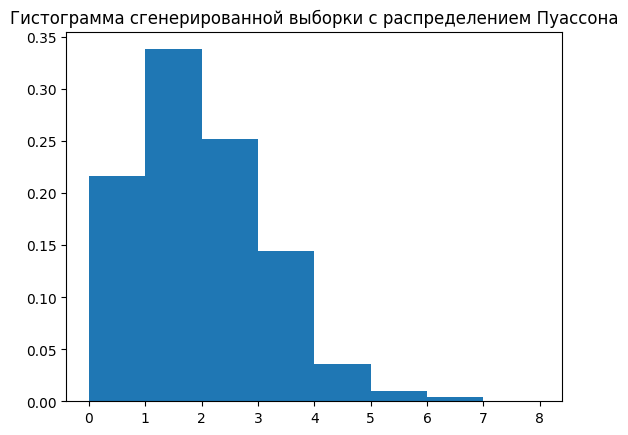

In [4]:
plt.hist(sample, bins = range(0, sample.max() + 3), density=True)
plt.title("Гистограмма сгенерированной выборки с распределением Пуассона")
plt.show()

Библиотека для построения класса-наследника c логарифмической функцией правдоподобия nloglikeobs:

In [5]:
from statsmodels.base.model import GenericLikelihoodModel

In [6]:
class Poisson(GenericLikelihoodModel):
    def nloglikeobs(self, params):
        # функция возвращает вероятность значения x пуассоновской случайной величины с параметрами *params
        return -np.log(stats.poisson.pmf(self.endog, *params)).sum()

Подгонка модели, а именно максимизация функции правдоподобия в базовом классе:

In [7]:
res = Poisson(sample).fit(start_params=1.0)
print("Истинное значение параметра lambda = ", lam)
lamML = res.params
print("Оценка ММП: lambda* = ", lamML[0], " при значении функции правдоподобия ", res.llf)

Optimization terminated successfully.
         Current function value: 1.516313
         Iterations: 15
         Function evaluations: 30
Истинное значение параметра lambda =  1.5
Оценка ММП: lambda* =  1.4919921875000013  при значении функции правдоподобия  -758.1565003003432


Оптимизация прошла успешно, итерационный процесс сошелся. 

`Current function value` - достигнутое минимальное значение целевой функции, то есть среднего отрицательного логарифма правдоподобия на одно наблюдение.

Полученная оценка ММП близка к истинному значению лямбды. 

Построение левой части уравнения для метода моментов:

In [8]:
from scipy.optimize import fsolve

In [9]:
def poissonMMeq(par):
    # теоретическое матожидание пуассоновского распределения
    exp = stats.poisson.mean(*par)
    # выборочное среднее
    mean = sample.mean()
    return (exp - mean)

lam_MM = fsolve(poissonMMeq, 1.0)
print("Оценка по методу моментов: lambda* = ", lam_MM[0])

lam_Est = sample.mean()
print("Выборочное среднее как оценка параметра: lambda* = ", lam_Est)


Оценка по методу моментов: lambda* =  1.492
Выборочное среднее как оценка параметра: lambda* =  1.492


Доверительный интервал 90% для оценки вероятности:

In [10]:
def poisson_confidence_interval(lam, size, confidence = 0.90):
    eps = stats.norm.ppf((1 + confidence) / 2.) / size**0.5 * lam**0.5
    return (lam - eps, lam + eps)

print("Доверительный 90%-ный интервал: ", poisson_confidence_interval(lam_Est, size))

Доверительный 90%-ный интервал:  (np.float64(1.4021482239072554), np.float64(1.5818517760927446))


Таким образом, выборочное среднее и выборочная дисперсия полученной сгенерированной выборки близки к теоретическому значению. Оценка ММП совпадает с оценкой метода моментов и равна выборочному среднему. Построенный доверительный интервал на уровне 90% накрывает истинное значение $\lambda$ = 1,5. 

#### Пункт 2. 

Генерация выборки объема 1000 наблюдений с геометрическим распределением с параметром 0.43

In [11]:
size = 1000
p = 0.43

sample = np.random.geometric(p, size)

print("Выборочное среднее: ", sample.mean())
print("Выборочная дисперсия: ", sample.var(ddof=1).round(5))

Выборочное среднее:  2.318
Выборочная дисперсия:  3.06194


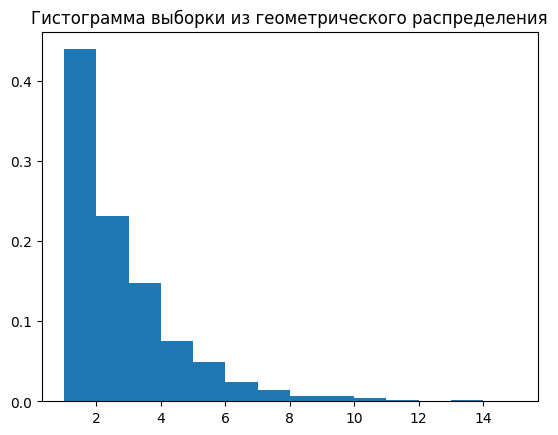

In [12]:
plt.hist(sample, bins = range(1, sample.max() + 3), density=True)
plt.title("Гистограмма выборки из геометрического распределения")
plt.show()

Модель максимального правдопобия для геометрического распределения, оценка ММП для параметра p:

In [13]:
class Geom(GenericLikelihoodModel):
    def loglike(self, params):
        return np.log(stats.geom.pmf(self.endog, *params)).sum()

res = Geom(sample).fit(start_params = 0.5)

print("Истинное значение вероятности p = ", p)
pML = res.params
print("Оценка ММП: p* = ", pML[0].round(6), " при значении функции правдоподобия ", res.llf.round(6))

Optimization terminated successfully.
         Current function value: 1.584833
         Iterations: 11
         Function evaluations: 22
Истинное значение вероятности p =  0.43
Оценка ММП: p* =  0.431445  при значении функции правдоподобия  -1584.833461


Определение надежности оценки при заданной точности:

In [14]:
def geom_rel(p, size, eps):
    err = p * (1 - p)**0.5 / size**0.5
    return 2 * stats.norm.cdf(eps / err) - 1

eps = 0.05
print("Надежность оценки при точности eps = 0.05: ", geom_rel(pML[0], size, eps).round(8))

Надежность оценки при точности eps = 0.05:  0.99999883


Таким образом, выборочные средние и дисперсия близки к теоретическим значениям для геометрического распределения с $p = 0.43$
Оценка ММП близка к истинному значению параметра $p$.
При точности 0.05 и объеме выборке в 1000 наблюдений надежность оценки составила $\approx$ 0.99999851